Compuerta (00)  (01)  (10)  (11)  Épocas    Convergió   Pesos             Bias
------------------------------------------------------------------------------------------
AND       0     0     0     1     4         Sí          [0.2 0.1]         -0.200
OR        0     1     1     1     4         Sí          [0.1 0.1]         -0.100
XOR       1     1     0     0     50        No          [-0.1  0. ]       0.000


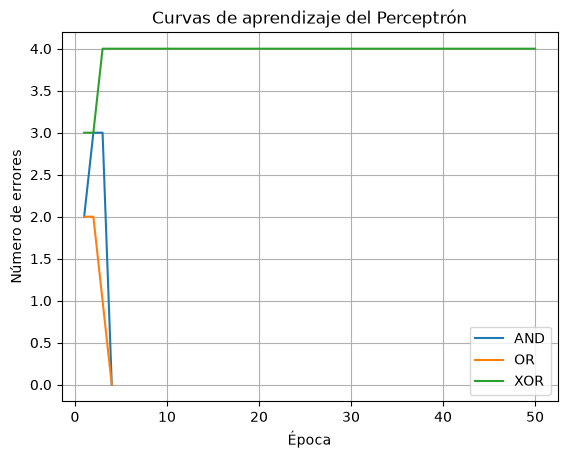

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)


X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y_OR = np.array([0, 1, 1, 1])
y_XOR = np.array([0, 1, 1, 0])
y_AND = np.array([0, 0, 0, 1])

compuertas = {
    "AND": np.array([0, 0, 0, 1]),
    "OR":  np.array([0, 1, 1, 1]),
    "XOR": np.array([0, 1, 1, 0])
}



def escalon(z):
    return 1 if z >= 0 else 0


def entrena_perceptron(X, y, eta=0.1, T=50):
    w = np.zeros(X.shape[1])
    b = 0.0
    historial = []

    for epoca in range(T):
        errores = 0

        for x, respuesta_correcta in zip(X, y):
            z = np.dot(w, x) + b
            prediccion = escalon(z)

            error = respuesta_correcta - prediccion

            w = w + eta * error * x
            b = b + eta * error

            errores += abs(error)

        historial.append(int(errores))

        if errores == 0:
            break

    return w, b, historial


def predecir(X, w, b):
    predicciones = []

    for x in X:
        z = np.dot(w, x) + b
        predicciones.append(escalon(z))

    return np.array(predicciones)



resultados = {}

for nombre, y in compuertas.items():
    w, b, historial = entrena_perceptron(X, y)

    predicciones = predecir(X, w, b)

    resultados[nombre] = {
        "w": w,
        "b": b,
        "historial": historial,
        "predicciones": predicciones
    }



print(
    f"{'Compuerta':<10}"
    f"{'(00)':<6}"
    f"{'(01)':<6}"
    f"{'(10)':<6}"
    f"{'(11)':<6}"
    f"{'Épocas':<10}"
    f"{'Convergió':<12}"
    f"{'Pesos':<18}"
    f"Bias"
)

print("-" * 90)

for nombre, resultado in resultados.items():
    p = resultado["predicciones"]
    convergio = resultado["historial"][-1] == 0

    print(
        f"{nombre:<10}"
        f"{p[0]:<6}"
        f"{p[1]:<6}"
        f"{p[2]:<6}"
        f"{p[3]:<6}"
        f"{len(resultado['historial']):<10}"
        f"{('Sí' if convergio else 'No'):<12}"
        f"{str(np.round(resultado['w'], 3)):<18}"
        f"{resultado['b']:.3f}"
    )


for nombre, resultado in resultados.items():
    historial = resultado["historial"]

    plt.plot(
        range(1, len(historial) + 1),
        historial,
        label=nombre
    )

plt.xlabel("Época")
plt.ylabel("Número de errores")
plt.title("Curvas de aprendizaje del Perceptrón")
plt.legend()
plt.grid()

plt.show()




### P1. Análisis del Perceptrón y de XOR

En los resultados, AND y OR clasifican correctamente las cuatro entradas y convergen en 4 épocas. XOR llega al límite de 50 épocas sin converger, con predicciones `[1, 1, 0, 0]` frente a las etiquetas `[0, 1, 1, 0]`.

AND y OR son linealmente separables: una recta puede separar sus dos clases. En XOR, los puntos de la clase 1 están en dos esquinas opuestas y los de la clase 0 en las otras dos. Una única recta no puede separar esas clases. Por ello, la curva de errores del Perceptrón no se estabiliza en cero; aumentar el número de épocas no elimina esta limitación del modelo.


Compuerta (00)  (01)  (10)  (11)  J final       Pesos               Bias
-----------------------------------------------------------------------------------------------
AND       0     0     0     0     0.061908      [0.151 0.151]       0.095
OR        0     1     1     1     0.053427      [0.265 0.265]       0.360
XOR       0     0     0     0     0.135799      [0.114 0.114]       0.265


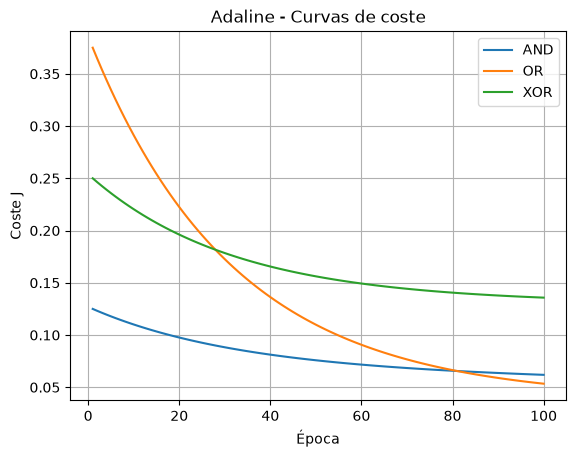

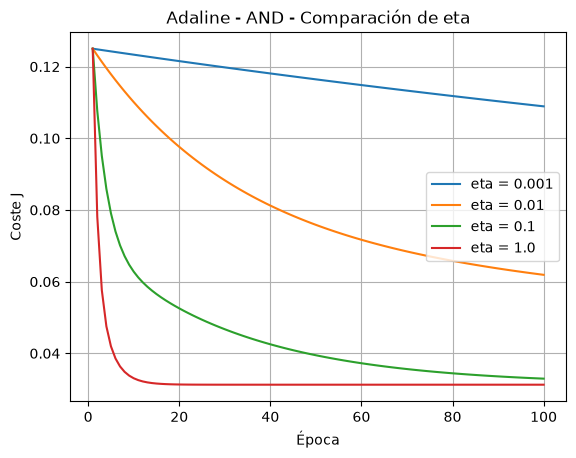

In [2]:

def entrena_adaline(X, y, eta=0.01, T=100):
    N = len(X)

    w = np.zeros(X.shape[1])
    b = 0.0
    historial = []

    for epoca in range(T):
        z = X @ w + b

        e = y - z

        w += eta * (X.T @ e) / N
        b += eta * e.sum() / N

        J = (e**2).sum() / (2 * N)
        historial.append(J)

    return w, b, historial


def predice_adaline(X, w, b):
    z = X @ w + b
    return np.where(z >= 0.5, 1, 0)



eta = 0.01
T = 100

resultados_adaline = {}

for nombre, y in compuertas.items():

    w, b, historial = entrena_adaline(
        X,
        y,
        eta=eta,
        T=T
    )

    predicciones = predice_adaline(
        X,
        w,
        b
    )

    resultados_adaline[nombre] = {
        "w": w,
        "b": b,
        "historial": historial,
        "predicciones": predicciones,
        "J_final": historial[-1]
    }



print(
    f"{'Compuerta':<10}"
    f"{'(00)':<6}"
    f"{'(01)':<6}"
    f"{'(10)':<6}"
    f"{'(11)':<6}"
    f"{'J final':<14}"
    f"{'Pesos':<20}"
    f"Bias"
)

print("-" * 95)

for nombre, resultado in resultados_adaline.items():
    p = resultado["predicciones"]

    print(
        f"{nombre:<10}"
        f"{p[0]:<6}"
        f"{p[1]:<6}"
        f"{p[2]:<6}"
        f"{p[3]:<6}"
        f"{resultado['J_final']:<14.6f}"
        f"{str(np.round(resultado['w'], 3)):<20}"
        f"{resultado['b']:.3f}"
    )



plt.figure()

for nombre, resultado in resultados_adaline.items():

    plt.plot(
        range(1, len(resultado["historial"]) + 1),
        resultado["historial"],
        label=nombre
    )

plt.xlabel("Época")
plt.ylabel("Coste J")
plt.title("Adaline - Curvas de coste")
plt.legend()
plt.grid()
plt.show()



etas = [0.001, 0.01, 0.1, 1.0]

plt.figure()

for eta_prueba in etas:

    w, b, historial = entrena_adaline(
        X,
        y_AND,
        eta=eta_prueba,
        T=100
    )

    plt.plot(
        range(1, len(historial) + 1),
        historial,
        label=f"eta = {eta_prueba}"
    )

plt.xlabel("Época")
plt.ylabel("Coste J")
plt.title("Adaline - AND - Comparación de eta")
plt.legend()
plt.grid()
plt.show()

### P2. Análisis de Adaline: tasa de aprendizaje y XOR

Con una tasa de aprendizaje `eta` demasiado pequeña, las actualizaciones son
pequeñas y el coste disminuye lentamente, por lo que pueden necesitarse muchas
más épocas. Al aumentar `eta`, el entrenamiento puede avanzar más rápido. Sin
embargo, una tasa excesivamente grande puede hacer que las actualizaciones
sobrepasen el mínimo, provocando oscilaciones o incluso divergencia.

En el experimento realizado con AND se compararon `eta = 0.001`, `0.01`,
`0.1` y `1.0`. Las tasas pequeñas producen una disminución más lenta del coste,
mientras que las mayores permiten avanzar más rápidamente. En el rango probado
las curvas permiten observar cómo la tasa de aprendizaje afecta directamente
a la velocidad y estabilidad del entrenamiento.

En XOR, el coste disminuye pero se mantiene en un valor positivo en lugar de
llegar a cero. Esto ocurre porque Adaline sigue siendo un modelo lineal y XOR
no es linealmente separable. El descenso de gradiente puede encontrar una
solución que reduzca el error cuadrático, pero no puede construir una única
frontera lineal que clasifique correctamente las cuatro entradas.

Compuerta Error   J final     J<0.01      Clasif.     4/4     Salidas finales
----------------------------------------------------------------------------------------------------
AND       MSE     0.024850    >500        109         Sí      [0.038  0.2361 0.2361 0.7076]
AND       CE      0.066880    >500        34          Sí      [8.00e-04 7.47e-02 7.47e-02 8.95e-01]
OR        MSE     0.015180    >500        121         Sí      [0.2693 0.8442 0.8442 0.9876]
OR        CE      0.037868    >500        40          Sí      [0.0817 0.9676 0.9676 0.9999]
XOR       MSE     0.125000    >500        Nunca       No      [0.5 0.5 0.5 0.5]
XOR       CE      0.693147    >500        Nunca       No      [0.5 0.5 0.5 0.5]


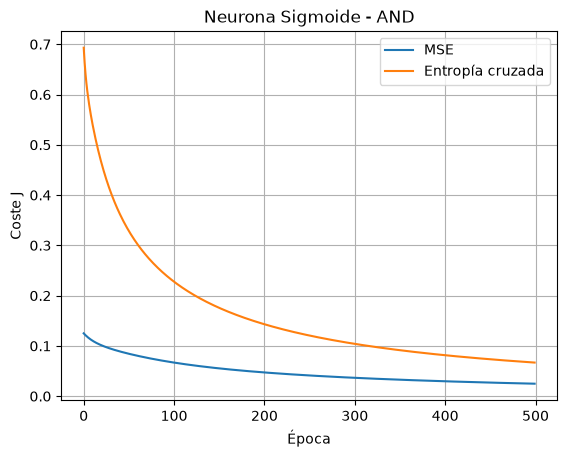

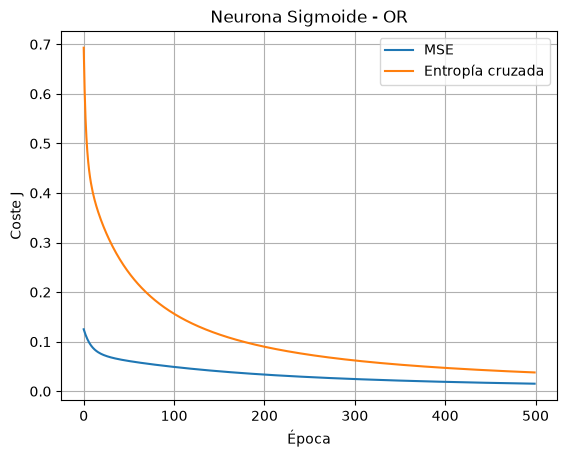

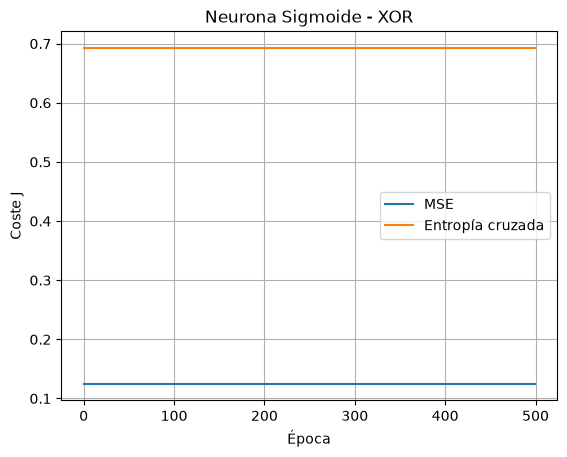

In [3]:
import numpy as np
import matplotlib.pyplot as plt



X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y_AND = np.array([0, 0, 0, 1])
y_OR  = np.array([0, 1, 1, 1])
y_XOR = np.array([0, 1, 1, 0])


compuertas = {
    "AND": y_AND,
    "OR": y_OR,
    "XOR": y_XOR
}



def sigmoide(z):
    return 1.0 / (1.0 + np.exp(-z))


def entrena_sigmoide(X, y, eta=0.5, T=500, tipo="CE"):
    N = len(X)

    w = np.zeros(X.shape[1])
    b = 0.0

    historial = []

    epoca_clasificacion_correcta = None
    epoca_error_001 = None

    # Evita log(0) en entropía cruzada
    eps = 1e-9

    for epoca in range(T):

        z = X @ w + b
        yhat = sigmoide(z)

        predicciones = np.where(yhat >= 0.5, 1, 0)

        # Primera época donde clasifica correctamente
        if (
            epoca_clasificacion_correcta is None
            and np.array_equal(predicciones, y)
        ):
            epoca_clasificacion_correcta = epoca + 1

        e = y - yhat

        if tipo == "CE":

            # El gradiente queda directamente como el error
            g = e

            J = -np.mean(
                y * np.log(yhat + eps)
                + (1 - y) * np.log(1 - yhat + eps)
            )

        else:

            # MSE arrastra la derivada de la sigmoide
            g = e * yhat * (1 - yhat)

            J = np.mean(e**2) / 2

        # Primera época donde el coste baja de 0.01
        if epoca_error_001 is None and J < 0.01:
            epoca_error_001 = epoca + 1

        w += eta * (X.T @ g) / N
        b += eta * g.sum() / N

        historial.append(J)

    return (
        w,
        b,
        historial,
        epoca_clasificacion_correcta,
        epoca_error_001
    )


def predice_sigmoide(X, w, b):
    probabilidades = sigmoide(X @ w + b)

    predicciones = np.where(
        probabilidades >= 0.5,
        1,
        0
    )

    return probabilidades, predicciones



eta = 0.5
T = 500

tipos_error = ["MSE", "CE"]

resultados_p3 = []


for nombre, y in compuertas.items():

    for tipo in tipos_error:

        w, b, historial, epoca_clasif, epoca_001 = entrena_sigmoide(
            X,
            y,
            eta=eta,
            T=T,
            tipo=tipo
        )

        probabilidades, predicciones = predice_sigmoide(
            X,
            w,
            b
        )

        clasifica_bien = np.array_equal(
            predicciones,
            y
        )

        resultados_p3.append({
            "compuerta": nombre,
            "error": tipo,
            "J_final": historial[-1],
            "epoca_001": epoca_001,
            "epoca_clasif": epoca_clasif,
            "clasifica_bien": clasifica_bien,
            "salidas": probabilidades,
            "historial": historial,
            "w": w,
            "b": b
        })



print(
    f"{'Compuerta':<10}"
    f"{'Error':<8}"
    f"{'J final':<12}"
    f"{'J<0.01':<12}"
    f"{'Clasif.':<12}"
    f"{'4/4':<8}"
    f"Salidas finales"
)

print("-" * 100)


for r in resultados_p3:

    epoca_001 = (
        str(r["epoca_001"])
        if r["epoca_001"] is not None
        else f">{T}"
    )

    epoca_clasif = (
        str(r["epoca_clasif"])
        if r["epoca_clasif"] is not None
        else "Nunca"
    )

    bien = (
        "Sí"
        if r["clasifica_bien"]
        else "No"
    )

    salidas = np.round(
        r["salidas"],
        4
    )

    print(
        f"{r['compuerta']:<10}"
        f"{r['error']:<8}"
        f"{r['J_final']:<12.6f}"
        f"{epoca_001:<12}"
        f"{epoca_clasif:<12}"
        f"{bien:<8}"
        f"{salidas}"
    )



for nombre in compuertas:

    resultado_mse = next(
        r for r in resultados_p3
        if r["compuerta"] == nombre
        and r["error"] == "MSE"
    )

    resultado_ce = next(
        r for r in resultados_p3
        if r["compuerta"] == nombre
        and r["error"] == "CE"
    )

    plt.figure()

    plt.plot(
        resultado_mse["historial"],
        label="MSE"
    )

    plt.plot(
        resultado_ce["historial"],
        label="Entropía cruzada"
    )

    plt.xlabel("Época")
    plt.ylabel("Coste J")

    plt.title(
        f"Neurona Sigmoide - {nombre}"
    )

    plt.legend()
    plt.grid()

    plt.show()

### P3. Comparación entre MSE y entropía cruzada (CE)

Con `eta = 0.5` y 500 épocas, CE alcanza por primera vez las cuatro clasificaciones correctas en la época 34 para AND y en la 40 para OR. MSE las alcanza en las épocas 109 y 121, respectivamente. Ambas pérdidas consiguen clasificar estas dos compuertas, pero CE lo hace antes y produce probabilidades finales más próximas a las etiquetas. Por estos criterios, CE ofrece mejores resultados en este experimento.

Las curvas muestran la evolución de cada función de coste. Sus valores finales no se comparan directamente para decidir cuál es mejor, porque MSE y CE tienen escalas y definiciones diferentes. Ninguna alcanza su propio umbral `J < 0.01` durante las 500 épocas, aunque AND y OR ya estén correctamente clasificadas.

**CE:** es adecuada para clasificación binaria y, combinada con la sigmoide, su gradiente evita el factor adicional `yhat * (1 - yhat)` de MSE. Esto favorece el aprendizaje cuando hay predicciones erróneas muy próximas a 0 o 1. Como desventaja, penaliza mucho los errores con alta confianza y exige cuidado numérico al calcular los logaritmos.

**MSE:** tiene una interpretación sencilla como error cuadrático y es útil para regresión. En esta clasificación aprende más despacio; su gradiente incluye la derivada de la sigmoide, que puede ser pequeña cuando la neurona se satura.

Para XOR, ambas pérdidas mantienen las salidas en 0.5 desde la inicialización simétrica utilizada y no consiguen las cuatro clasificaciones correctas. Los costes son 0.125 para MSE y aproximadamente 0.693147 para CE. Cambiar la pérdida no resuelve la falta de separabilidad lineal: una sola neurona sigmoide también tiene una frontera de decisión lineal.
